# 06 — Métricas, validação cruzada e curvas ROC/PR

**Objetivo:** consolidar as métricas da Aula 08 para todos os modelos, calcular os *gaps* com valores exatos, executar **validação cruzada K=5** para árvore e ensembles e gerar **matrizes de confusão** e **curvas ROC/PR** (com ênfase na classe *High*).

As predições vêm dos notebooks 03/04/05 — não há recálculo divergente.

In [1]:
import sys, json
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

from src.config import SEED, RISK_CLASSES, REPORTS_DIR, TABLES_DIR, FIGURES_DIR
from src.data import split_train_test, encode_target
from src.config import CLASSIFICATION_TARGET, REGRESSION_TARGET
from src import metrics

np.random.seed(SEED)
sns.set_theme(style='whitegrid')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = REPORTS_DIR / 'predictions'
MODELOS_DIR = REPORTS_DIR / 'models'
print('Semente:', SEED)

Semente: 42


## 1) Dados e predições salvas

Cada notebook anterior salvou `y_true`, `y_pred` e (na classificação) `y_proba`. Aqui os arquivos são apenas carregados — garantindo que as tabelas do relatório correspondam exatamente ao que foi executado.

In [2]:
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
df_clf = pd.read_csv('../data/processed/dataset_classification.csv')

Xr_train, Xr_test, yr_train, yr_test = split_train_test(df_reg, REGRESSION_TARGET, stratify=False)
Xc_train, Xc_test, yc_train_raw, yc_test_raw = split_train_test(df_clf, CLASSIFICATION_TARGET, stratify=True)
yc_train = encode_target(yc_train_raw)
yc_test = encode_target(yc_test_raw)

modelos_clf = {
    'Sistema Especialista': 'expert_classificacao',
    'Arvore de Decisao': 'tree_classificacao',
    'Ensemble (Random Forest)': 'rf_classificacao',
    'Ensemble (Gradient Boosting)': 'gb_classificacao',
}
modelos_reg = {
    'Sistema Especialista': 'expert_regressao',
    'Arvore de Decisao': 'tree_regressao',
    'Ensemble (Random Forest)': 'rf_regressao',
    'Ensemble (Gradient Boosting)': 'gb_regressao',
}

predicoes_clf = {nome: np.load(PRED_DIR / f'{arq}.npz') for nome, arq in modelos_clf.items()}
predicoes_reg = {nome: np.load(PRED_DIR / f'{arq}.npz') for nome, arq in modelos_reg.items()}

print('Modelos de classificação:', list(predicoes_clf))
print('Modelos de regressão:', list(predicoes_reg))

Modelos de classificação: ['Sistema Especialista', 'Arvore de Decisao', 'Ensemble (Random Forest)', 'Ensemble (Gradient Boosting)']
Modelos de regressão: ['Sistema Especialista', 'Arvore de Decisao', 'Ensemble (Random Forest)', 'Ensemble (Gradient Boosting)']


## 2) Métricas completas (treino e teste)

- **Classificação:** Accuracy, Precision/Recall/F1 (macro e weighted), ROC-AUC e PR-AUC (macro OVR).
- **Regressão:** MAE, MSE, RMSE, MAPE, R² e MedAE.

O **gap** é padronizado como *degradação*: `treino − teste` para métricas de qualidade (F1, accuracy, ROC-AUC, R²) e `teste − treino` para métricas de erro (MAE, MSE, RMSE, MAPE, MedAE). Valores positivos indicam piora no teste.

In [3]:
ORIENTACAO = {
    'F1 (macro)': 'qualidade', 'Accuracy': 'qualidade', 'ROC-AUC (OVR macro)': 'qualidade',
    'PR-AUC (macro)': 'qualidade', 'Precision (macro)': 'qualidade', 'Recall (macro)': 'qualidade',
    'R²': 'qualidade', 'MAE': 'erro', 'MSE': 'erro', 'RMSE': 'erro', 'MAPE (%)': 'erro', 'MedAE': 'erro',
}

def gap_degradacao(m_tr, m_te):
    saida = {}
    for chave, valor_tr in m_tr.items():
        if chave not in m_te or chave not in ORIENTACAO:
            continue
        if not isinstance(valor_tr, (int, float, np.floating, np.integer)):
            continue
        valor_te = float(m_te[chave])
        if ORIENTACAO[chave] == 'qualidade':
            saida[f'Gap {chave}'] = float(valor_tr) - valor_te
        else:
            saida[f'Gap {chave}'] = valor_te - float(valor_tr)
    return saida

metricas_clf = []
for nome, dados in predicoes_clf.items():
    m_tr = metrics.classification_metrics(dados['y_true_train'], dados['y_pred_train'], dados['y_proba_train'], classes=[0, 1, 2])
    m_te = metrics.classification_metrics(dados['y_true_test'], dados['y_pred_test'], dados['y_proba_test'], classes=[0, 1, 2])
    metricas_clf.append({'Familia': nome, 'Problema': 'Classificacao', 'Conjunto': 'Treino', **m_tr})
    metricas_clf.append({'Familia': nome, 'Problema': 'Classificacao', 'Conjunto': 'Teste', **m_te,
                         **gap_degradacao(m_tr, m_te)})
metricas_clf = pd.DataFrame(metricas_clf)

metricas_reg = []
for nome, dados in predicoes_reg.items():
    m_tr = metrics.regression_metrics(dados['y_true_train'], dados['y_pred_train'])
    m_te = metrics.regression_metrics(dados['y_true_test'], dados['y_pred_test'])
    metricas_reg.append({'Familia': nome, 'Problema': 'Regressao', 'Conjunto': 'Treino', **m_tr})
    metricas_reg.append({'Familia': nome, 'Problema': 'Regressao', 'Conjunto': 'Teste', **m_te,
                         **gap_degradacao(m_tr, m_te)})
metricas_reg = pd.DataFrame(metricas_reg)

metricas_clf.to_csv(TABLES_DIR / '06_metricas_classificacao.csv', index=False)
metricas_reg.to_csv(TABLES_DIR / '06_metricas_regressao.csv', index=False)

colunas_clf = ['Familia', 'Conjunto', 'Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)',
               'ROC-AUC (OVR macro)', 'PR-AUC (macro)', 'Gap F1 (macro)']
colunas_reg = ['Familia', 'Conjunto', 'MAE', 'MSE', 'RMSE', 'MAPE (%)', 'R²', 'MedAE', 'Gap RMSE']
print('CLASSIFICAÇÃO')
display(metricas_clf[colunas_clf].round(4))
print('REGRESSÃO')
display(metricas_reg[colunas_reg].round(4))

CLASSIFICAÇÃO


,Familia,Conjunto,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OVR macro),PR-AUC (macro),Gap F1 (macro)
0,Sistema Especialista,Treino,0.7920,0.7837,0.7914,0.7829,0.8844,0.7726,NaN
1,Sistema Especialista,Teste,0.7987,0.7913,0.7986,0.7907,0.8884,0.7796,-0.0078
2,Arvore de Decisao,Treino,0.8103,0.8062,0.7808,0.7903,0.9435,0.8536,NaN
3,Arvore de Decisao,Teste,0.8096,0.8066,0.7798,0.7899,0.9417,0.8498,0.0004
4,Ensemble (Random Forest),Treino,0.8630,0.8586,0.8470,0.8510,0.9684,0.9272,NaN
5,Ensemble (Random Forest),Teste,0.8179,0.8048,0.7966,0.8000,0.9463,0.8653,0.0511
6,Ensemble (Gradient Boosting),Treino,0.8184,0.8064,0.7979,0.8013,0.9477,0.8730,NaN
7,Ensemble (Gradient Boosting),Teste,0.8187,0.8056,0.7976,0.8009,0.9469,0.8671,0.0005


REGRESSÃO


,Familia,Conjunto,MAE,MSE,RMSE,MAPE (%),R²,MedAE,Gap RMSE
0,Sistema Especialista,Treino,13.0963,250.2224,15.8184,85.1674,0.6358,11.9749,NaN
1,Sistema Especialista,Teste,13.1626,250.6768,15.8328,92.5491,0.6367,11.9892,0.0144
2,Arvore de Decisao,Treino,7.6301,81.7267,9.0403,36.7000,0.8810,6.9735,NaN
3,Arvore de Decisao,Teste,7.7679,83.9369,9.1617,39.0485,0.8784,7.2214,0.1214
4,Ensemble (Random Forest),Treino,6.8073,64.1208,8.0075,32.4165,0.9067,6.3026,NaN
5,Ensemble (Random Forest),Teste,7.5587,78.1057,8.8377,37.8820,0.8868,7.1666,0.8302
6,Ensemble (Gradient Boosting),Treino,7.5243,78.2134,8.8438,36.2233,0.8862,6.9913,NaN
7,Ensemble (Gradient Boosting),Teste,7.6073,79.3224,8.9063,37.8968,0.8850,7.2081,0.0625


## 3) Verificação dos gaps com valores exatos

O relatório anterior apresentava divergências porque subtraía valores já arredondados. Abaixo o gap é recalculado diretamente dos arrays de predição, sem arredondamento intermediário.

In [4]:
linhas_gap = []
for nome, dados in predicoes_clf.items():
    f1_tr = metrics.classification_metrics(dados['y_true_train'], dados['y_pred_train'])['F1 (macro)']
    f1_te = metrics.classification_metrics(dados['y_true_test'], dados['y_pred_test'])['F1 (macro)']
    linhas_gap.append({'Familia': nome, 'Problema': 'Classificacao',
                       'Metrica': 'F1-macro', 'Treino_exato': f1_tr, 'Teste_exato': f1_te,
                       'Gap_exato': f1_tr - f1_te})
for nome, dados in predicoes_reg.items():
    rmse_tr = metrics.regression_metrics(dados['y_true_train'], dados['y_pred_train'])['RMSE']
    rmse_te = metrics.regression_metrics(dados['y_true_test'], dados['y_pred_test'])['RMSE']
    linhas_gap.append({'Familia': nome, 'Problema': 'Regressao',
                       'Metrica': 'RMSE', 'Treino_exato': rmse_tr, 'Teste_exato': rmse_te,
                       'Gap_exato': rmse_te - rmse_tr})

gaps_exatos = pd.DataFrame(linhas_gap)
gaps_exatos['Treino_arredondado'] = gaps_exatos['Treino_exato'].round(4)
gaps_exatos['Teste_arredondado'] = gaps_exatos['Teste_exato'].round(4)
gaps_exatos['Gap_pelas_colunas_arredondadas'] = (
    (gaps_exatos['Treino_arredondado'] - gaps_exatos['Teste_arredondado'])
    * np.where(gaps_exatos['Problema'] == 'Classificacao', 1, -1)
)
gaps_exatos.to_csv(TABLES_DIR / '06_gaps_exatos.csv', index=False)
gaps_exatos.round(6)

,Familia,Problema,Metrica,Treino_exato,Teste_exato,Gap_exato,Treino_arredondado,Teste_arredondado,Gap_pelas_colunas_arredondadas
0,Sistema Especialista,Classificacao,F1-macro,0.782946,0.790747,-0.007800,0.7829,0.7907,-0.0078
1,Arvore de Decisao,Classificacao,F1-macro,0.790304,0.789856,0.000448,0.7903,0.7899,0.0004
2,Ensemble (Random Forest),Classificacao,F1-macro,0.851050,0.799978,0.051072,0.8510,0.8000,0.0510
3,Ensemble (Gradient Boosting),Classificacao,F1-macro,0.801341,0.800871,0.000470,0.8013,0.8009,0.0004
4,Sistema Especialista,Regressao,RMSE,15.818419,15.832775,0.014355,15.8184,15.8328,0.0144
5,Arvore de Decisao,Regressao,RMSE,9.040282,9.161711,0.121429,9.0403,9.1617,0.1214
6,Ensemble (Random Forest),Regressao,RMSE,8.007548,8.837744,0.830195,8.0075,8.8377,0.8302
7,Ensemble (Gradient Boosting),Regressao,RMSE,8.843833,8.906313,0.062480,8.8438,8.9063,0.0625


## 4) Matrizes de confusão (teste)

Uma matriz por modelo de classificação, com contagens absolutas. A classe **High** é a de maior interesse prático (falso negativo = risco alto não detectado).

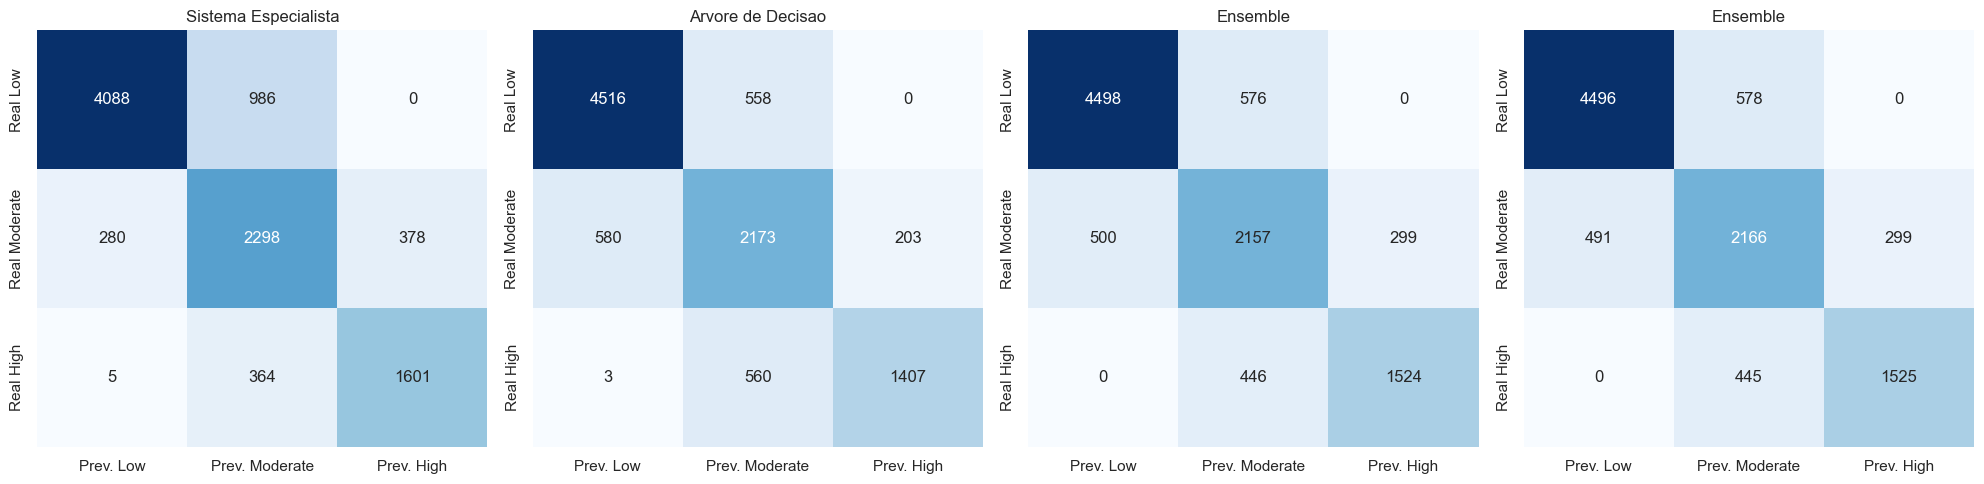

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (nome, dados) in zip(axes, predicoes_clf.items()):
    cm = metrics.confusion_matrix_frame(dados['y_true_test'], dados['y_pred_test'], classes=RISK_CLASSES)
    matriz = cm.set_index('').to_numpy()
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=[f'Prev. {c}' for c in RISK_CLASSES],
                yticklabels=[f'Real {c}' for c in RISK_CLASSES])
    ax.set_title(nome.split(' (')[0])
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_matrizes_confusao.png', dpi=200, bbox_inches='tight')
plt.show()

In [6]:
# Relatório por classe — foco em High
por_classe = []
for nome, dados in predicoes_clf.items():
    tabela = metrics.per_class_report(dados['y_true_test'], dados['y_pred_test'], classes=RISK_CLASSES)
    tabela.insert(0, 'Familia', nome)
    por_classe.append(tabela)
por_classe = pd.concat(por_classe, ignore_index=True)
por_classe.to_csv(TABLES_DIR / '06_por_classe.csv', index=False)

print('Classe High (recall = proporção de risco alto corretamente detectado):')
display(por_classe[por_classe['Classe'] == 'High'].round(4))

Classe High (recall = proporção de risco alto corretamente detectado):


,Familia,Classe,Suporte,Precision,Recall,F1
2,Sistema Especialista,High,1970,0.8090,0.8127,0.8108
5,Arvore de Decisao,High,1970,0.8739,0.7142,0.7860
8,Ensemble (Random Forest),High,1970,0.8360,0.7736,0.8036
11,Ensemble (Gradient Boosting),High,1970,0.8361,0.7741,0.8039


## 5) Curvas ROC e Precision-Recall

ROC e PR são calculadas em esquema *one-vs-rest* macro (ROC) e para a classe **High** (PR). O sistema especialista usa pseudo-probabilidades normalizadas dos votos — por isso sua curva é mais grosseira, o que é esperado.

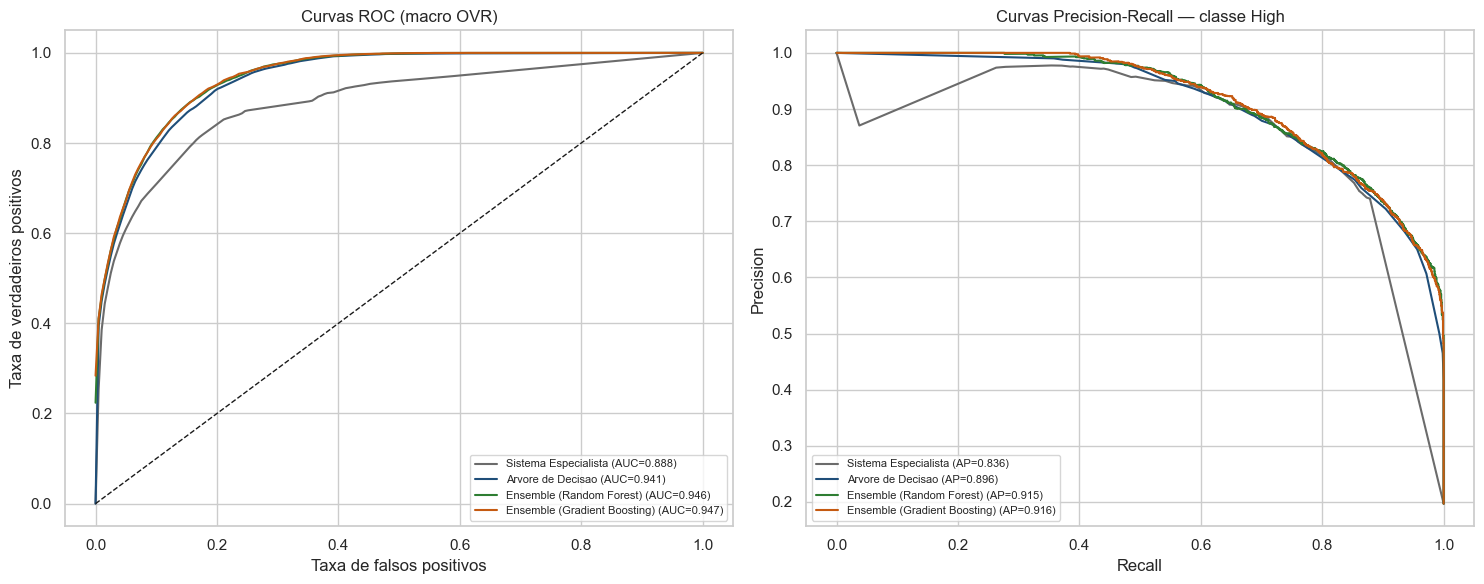

In [7]:
y_bin = label_binarize(yc_test, classes=[0, 1, 2])
cores = {'Sistema Especialista': '#6b6b6b', 'Arvore de Decisao': '#1f4e79',
         'Ensemble (Random Forest)': '#2e7d32', 'Ensemble (Gradient Boosting)': '#c55a11'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for nome, dados in predicoes_clf.items():
    proba = dados['y_proba_test']
    # ROC macro
    fpr_all, tpr_all = [], []
    for classe in range(3):
        fpr, tpr, _ = roc_curve(y_bin[:, classe], proba[:, classe])
        fpr_all.append(fpr); tpr_all.append(tpr)
    grid = np.linspace(0, 1, 200)
    tpr_interp = np.mean([np.interp(grid, fpr, tpr) for fpr, tpr in zip(fpr_all, tpr_all)], axis=0)
    auc_macro = auc(grid, tpr_interp)
    axes[0].plot(grid, tpr_interp, label=f'{nome} (AUC={auc_macro:.3f})', color=cores[nome])

    # PR da classe High
    precisao, recall, _ = precision_recall_curve(y_bin[:, 2], proba[:, 2])
    ap = average_precision_score(y_bin[:, 2], proba[:, 2])
    axes[1].plot(recall, precisao, label=f'{nome} (AP={ap:.3f})', color=cores[nome])

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_xlabel('Taxa de falsos positivos'); axes[0].set_ylabel('Taxa de verdadeiros positivos')
axes[0].set_title('Curvas ROC (macro OVR)'); axes[0].legend(fontsize=8)

axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Curvas Precision-Recall — classe High'); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_curvas_roc_pr.png', dpi=200, bbox_inches='tight')
plt.show()

## 6) Validação cruzada K=5 (árvore e ensembles)

A validação cruzada é feita **sobre o conjunto de treino** (o teste permanece intocado). Classificação: `StratifiedKFold`; regressão: `KFold`. Reporta-se média e desvio-padrão entre folds.

O sistema especialista não entra na CV porque não possui treinamento estatístico — suas regras são fixas.

In [8]:
with open(MODELOS_DIR / 'tree_params.json', encoding='utf-8') as f:
    tree_params = json.load(f)
with open(MODELOS_DIR / 'ensemble_meta.json', encoding='utf-8') as f:
    ensemble_meta = json.load(f)

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)

estimadores_clf = {
    'Arvore de Decisao': DecisionTreeClassifier(random_state=SEED, **tree_params['classificacao']),
    'Ensemble (Random Forest)': RandomForestClassifier(random_state=SEED, n_jobs=1, **ensemble_meta['rf_classificacao']),
    'Ensemble (Gradient Boosting)': GradientBoostingClassifier(random_state=SEED, **ensemble_meta['gb_classificacao']),
}
estimadores_reg = {
    'Arvore de Decisao': DecisionTreeRegressor(random_state=SEED, **tree_params['regressao']),
    'Ensemble (Random Forest)': RandomForestRegressor(random_state=SEED, n_jobs=1, **ensemble_meta['rf_regressao']),
    'Ensemble (Gradient Boosting)': GradientBoostingRegressor(random_state=SEED, **ensemble_meta['gb_regressao']),
}

scoring_clf = {'F1_macro': 'f1_macro', 'Accuracy': 'accuracy'}
scoring_reg = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'R2': 'r2'}

linhas_cv = []
for nome, estimador in estimadores_clf.items():
    resultado = cross_validate(estimador, Xc_train, yc_train, cv=cv_clf, scoring=scoring_clf, n_jobs=4)
    for metrica in scoring_clf:
        linhas_cv.append({'Familia': nome, 'Problema': 'Classificacao', 'Metrica': metrica,
                          'Media': float(resultado[f'test_{metrica}'].mean()),
                          'Desvio_padrao': float(resultado[f'test_{metrica}'].std(ddof=1))})

for nome, estimador in estimadores_reg.items():
    resultado = cross_validate(estimador, Xr_train, yr_train, cv=cv_reg, scoring=scoring_reg, n_jobs=4)
    for metrica in scoring_reg:
        valores = resultado[f'test_{metrica}']
        if metrica in ['RMSE', 'MAE']:
            valores = -valores
        linhas_cv.append({'Familia': nome, 'Problema': 'Regressao', 'Metrica': metrica,
                          'Media': float(valores.mean()), 'Desvio_padrao': float(valores.std(ddof=1))})

validacao_cruzada = pd.DataFrame(linhas_cv)
validacao_cruzada.to_csv(TABLES_DIR / '06_validacao_cruzada.csv', index=False)
validacao_cruzada.round(4)

,Familia,Problema,Metrica,Media,Desvio_padrao
0,Arvore de Decisao,Classificacao,F1_macro,0.7870,0.0033
1,Arvore de Decisao,Classificacao,Accuracy,0.8055,0.0048
2,Ensemble (Random Forest),Classificacao,F1_macro,0.7962,0.0045
3,Ensemble (Random Forest),Classificacao,Accuracy,0.8142,0.0036
4,Ensemble (Gradient Boosting),Classificacao,F1_macro,0.7966,0.0038
5,Ensemble (Gradient Boosting),Classificacao,Accuracy,0.8144,0.0028
6,Arvore de Decisao,Regressao,RMSE,9.1756,0.0770
7,Arvore de Decisao,Regressao,MAE,7.7330,0.0616
8,Arvore de Decisao,Regressao,R2,0.8774,0.0023
9,Ensemble (Random Forest),Regressao,RMSE,8.8519,0.0628


In [9]:
# Tabela resumida: métrica principal por modelo (média ± dp)
principal = validacao_cruzada[validacao_cruzada['Metrica'].isin(['F1_macro', 'RMSE'])].copy()
principal['Media ± dp'] = principal.apply(
    lambda r: f"{r['Media']:.4f} ± {r['Desvio_padrao']:.4f}", axis=1)
principal[['Familia', 'Problema', 'Metrica', 'Media', 'Desvio_padrao', 'Media ± dp']]

,Familia,Problema,Metrica,Media,Desvio_padrao,Media ± dp
0,Arvore de Decisao,Classificacao,F1_macro,0.786977,0.003294,0.7870 ± 0.0033
2,Ensemble (Random Forest),Classificacao,F1_macro,0.796195,0.004498,0.7962 ± 0.0045
4,Ensemble (Gradient Boosting),Classificacao,F1_macro,0.796615,0.003844,0.7966 ± 0.0038
6,Arvore de Decisao,Regressao,RMSE,9.175594,0.076974,9.1756 ± 0.0770
9,Ensemble (Random Forest),Regressao,RMSE,8.851932,0.062834,8.8519 ± 0.0628
12,Ensemble (Gradient Boosting),Regressao,RMSE,8.911548,0.049550,8.9115 ± 0.0496


## 7) Consolidação para o relatório

As tabelas finais (2a e 2b) são geradas a partir destes arquivos no notebook 07, junto com os dados de eficiência. Aqui já se verifica a coerência: gaps exatos, métricas completas e CV.

In [10]:
# Quadro-resumo do teste (todas as métricas exigidas)
resumo_clf = metricas_clf[metricas_clf['Conjunto'] == 'Teste'][[
    'Familia', 'Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)',
    'ROC-AUC (OVR macro)', 'PR-AUC (macro)', 'Gap F1 (macro)']].copy()
resumo_reg = metricas_reg[metricas_reg['Conjunto'] == 'Teste'][[
    'Familia', 'MAE', 'MSE', 'RMSE', 'MAPE (%)', 'R²', 'MedAE', 'Gap RMSE']].copy()

resumo_clf.to_csv(TABLES_DIR / '06_resumo_classificacao.csv', index=False)
resumo_reg.to_csv(TABLES_DIR / '06_resumo_regressao.csv', index=False)

print('Tabela 2a (classificação)'); display(resumo_clf.round(4))
print('Tabela 2b (regressão)'); display(resumo_reg.round(4))

Tabela 2a (classificação)


,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OVR macro),PR-AUC (macro),Gap F1 (macro)
1,Sistema Especialista,0.7987,0.7913,0.7986,0.7907,0.8884,0.7796,-0.0078
3,Arvore de Decisao,0.8096,0.8066,0.7798,0.7899,0.9417,0.8498,0.0004
5,Ensemble (Random Forest),0.8179,0.8048,0.7966,0.8000,0.9463,0.8653,0.0511
7,Ensemble (Gradient Boosting),0.8187,0.8056,0.7976,0.8009,0.9469,0.8671,0.0005


Tabela 2b (regressão)


,Familia,MAE,MSE,RMSE,MAPE (%),R²,MedAE,Gap RMSE
1,Sistema Especialista,13.1626,250.6768,15.8328,92.5491,0.6367,11.9892,0.0144
3,Arvore de Decisao,7.7679,83.9369,9.1617,39.0485,0.8784,7.2214,0.1214
5,Ensemble (Random Forest),7.5587,78.1057,8.8377,37.8820,0.8868,7.1666,0.8302
7,Ensemble (Gradient Boosting),7.6073,79.3224,8.9063,37.8968,0.8850,7.2081,0.0625


## 8) Interpretação

- **Classificação:** Gradient Boosting e Random Forest ficam praticamente empatados em F1-macro (~0,80), mas o *gap* do Gradient Boosting é muito menor (≈0,0005 contra ≈0,051).
- **Classe High:** o recall dessa classe é o indicador mais crítico; a matriz de confusão mostra quantos casos de risco alto passam despercebidos.
- **Regressão:** Random Forest tem o menor RMSE no teste, mas *gap* grande; Gradient Boosting tem RMSE ligeiramente maior e *gap* quase nulo — melhor generalização.
- **CV K=5:** confirma a estabilidade das estimativas e permite comparar média ± desvio-padrão, como exigido.